In [27]:
pacman::p_load(ggplot2,tidyverse,patchwork)

In [28]:
scaling_relationships=read.csv("../data/merged_results.csv") %>%
    dplyr::filter(!(is.na(metaT_p_half_sat)&is.na(metaT_n_half_sat)))

In [29]:
unique(scaling_relationships$taxon)

[1] "Mamiellales"          "Leptocylindrales"     "Cryptomonadales"     
 [4] "Prymnesiales"         "Suessiales"           "Hemiaulales"         
 [7] "Chaetocerotophycidae" "Rhizosoleniales"      "Gymnodiniales"       
[10] "Coscinodiscales"      "Gonyaulacales"        "Bacillariales"       
[13] "Thalassiosirales"     "Phaeocystales"        "Isochrysidales"      
[16] "Melosirales"          "Lithodesmiales"       "Pyramimonadales_X"   
[19] "Parmales"             "Prorocentrales"

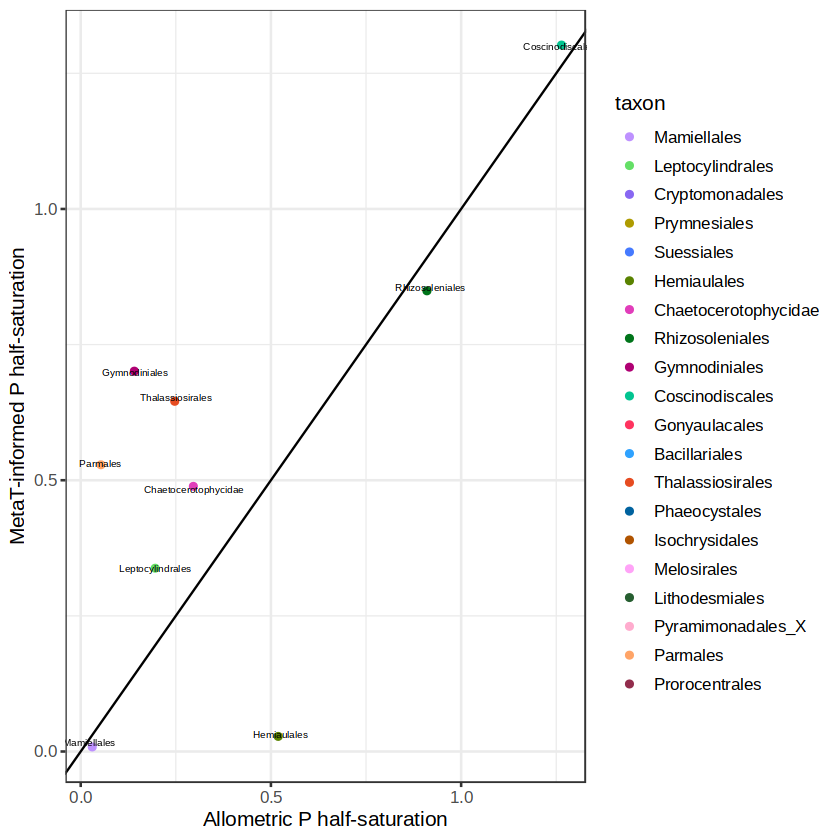

In [30]:
p_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(taxon=factor(taxon))%>%
                   dplyr::filter(metaT_p_half_sat>0))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_p,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_text(aes(x=half_sat_p,
                   y=metaT_p_half_sat,
                   label=taxon),
               position="jitter",size=2) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE)+ 
    xlab("Allometric P half-saturation")+
    ylab("MetaT-informed P half-saturation")
p_half_sat

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text()`).”


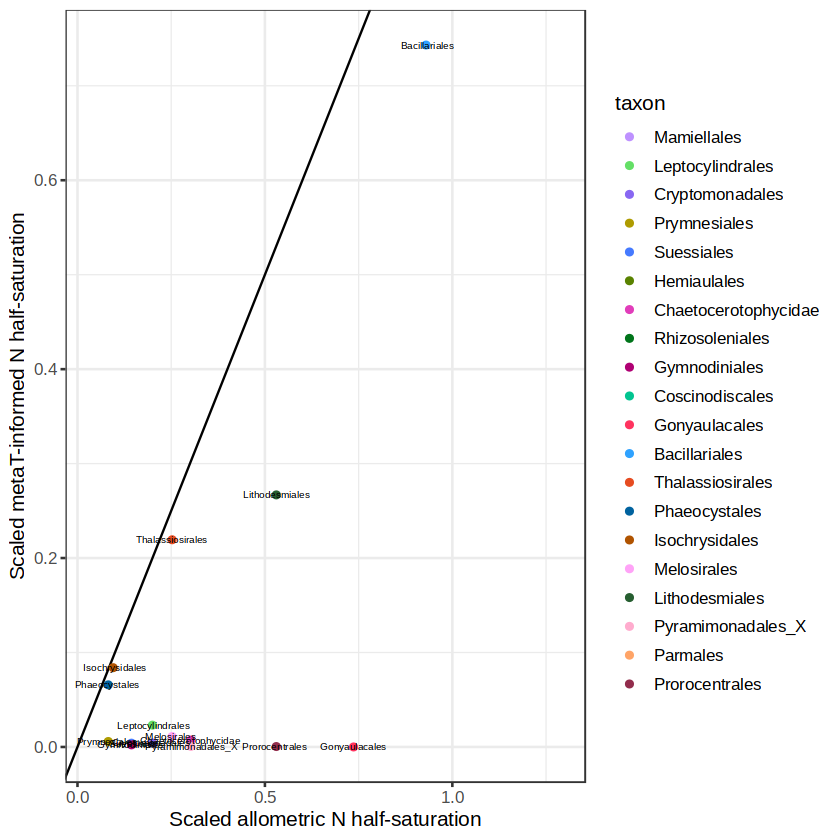

In [31]:
n_half_sat = ggplot(scaling_relationships)+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend=TRUE)+
     geom_text(aes(x=half_sat_n/16,
                   y=metaT_n_half_sat/16,
                   label=taxon),
               position="jitter",size=2) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation")
n_half_sat

In [32]:
summary(lm(half_sat_p~metaT_p_half_sat,data=scaling_relationships))


Call:
lm(formula = half_sat_p ~ metaT_p_half_sat, data = scaling_relationships)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.37981 -0.23332 -0.06157  0.28200  0.48662 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)  
(Intercept)       0.01234    0.18840   0.065    0.950  
metaT_p_half_sat  0.72527    0.28412   2.553    0.038 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3242 on 7 degrees of freedom
  (11 observations deleted due to missingness)
Multiple R-squared:  0.4821,	Adjusted R-squared:  0.4081 
F-statistic: 6.516 on 1 and 7 DF,  p-value: 0.03795


In [19]:
summary(lm(metaT_n_half_sat~half_sat_n,data=scaling_relationships))


Call:
lm(formula = metaT_n_half_sat ~ half_sat_n, data = scaling_relationships)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.9182 -1.0502 -0.0802  1.2305  5.4050 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept)  -1.0517     1.0573  -0.995  0.33801   
half_sat_n    0.5066     0.1644   3.082  0.00875 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.492 on 13 degrees of freedom
  (5 observations deleted due to missingness)
Multiple R-squared:  0.4222,	Adjusted R-squared:  0.3777 
F-statistic: 9.498 on 1 and 13 DF,  p-value: 0.008746


In [25]:
p_merge = (n_half_sat | p_half_sat) + plot_layout(guides = "collect") & plot_annotation(tag_levels = "A")
ggsave("../figures/half_sats.png",plot=p_merge,width=10,height=6,units="in")

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text()`).”


In [26]:
ggsave("../figures/half_sats.pdf",plot=p_merge,width=12,height=6,units="in")

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text()`).”


Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text()`).”


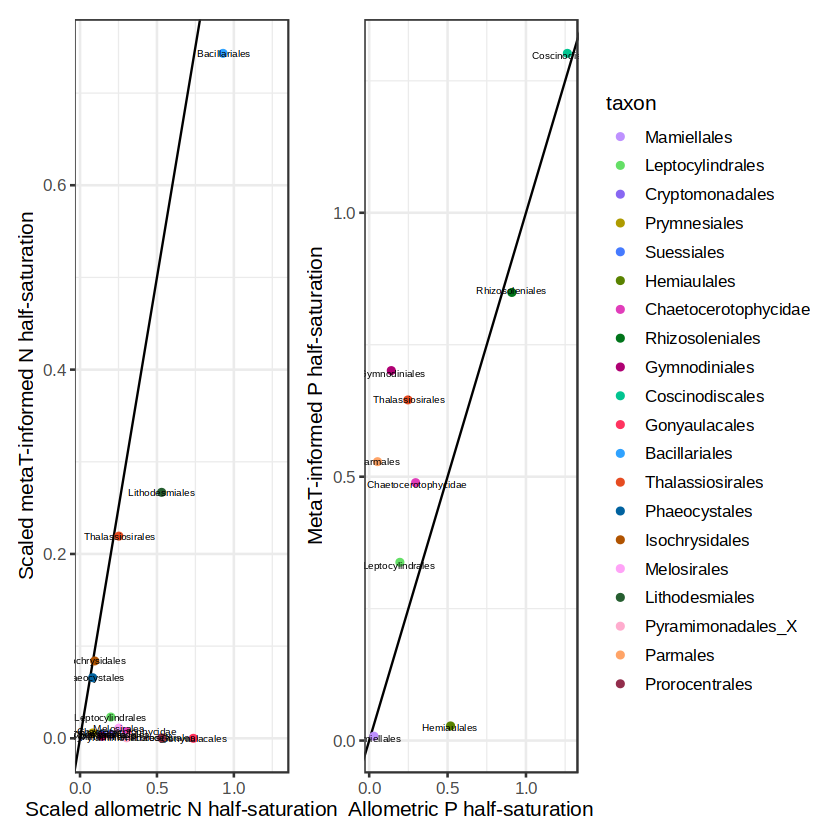

In [22]:
p_merge